# Fase 5: cenários para 2030

Projeta a potência de MMGD instalada no Sudeste até dez/2030, com leque de incerteza, a partir do modelo escolhido na fase 4.

Entrada: `data/processed/aneel_serie_mensal_uf.parquet`. Modelos em [`src/modelos.py`](../src/modelos.py).
Referência: FPP3 §5.6 (retransformação e correção de viés), §13.5 (intervalos de previsão para agregados), cap. 11
(previsão hierárquica e reconciliação); Sklar (1959) e Wickramasuriya, Athanasopoulos & Hyndman (2019, MinT).
Os comentários foram escritos com o retrato da ANEEL de out/2026 (série até jun/2026).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import estilo
import modelos as M
from estilo import CORES_UF, UFS

%matplotlib inline
estilo.aplicar()
warnings.simplefilter("ignore")
pd.set_option("display.precision", 2)

RES = ROOT / "resultados"
NOS = ["SE", *UFS]
serie, y = M.carregar(ROOT / "data" / "processed" / "aneel_serie_mensal_uf.parquet")
acum = {uf: serie[serie.uf == uf]["mw_acumulado"].iloc[-1] for uf in NOS}
FIM = y["SE"].index[-1]
H = (2030 - FIM.year) * 12 + 12 - FIM.month   # até dez/2030
N_SIM = 4000
FUT = M.futuro(y["SE"], H)
print(f"série até {FIM:%Y-%m}; horizonte {FUT[0]:%Y-%m} a {FUT[-1]:%Y-%m} ({H} meses)")
print(f"acumulado em {FIM:%m/%Y}: Sudeste {acum['SE'] / 1e3:.2f} GW")

série até 2026-06; horizonte 2026-07 a 2030-12 (54 meses)
acumulado em 06/2026: Sudeste 16.65 GW


## 1. Modelo e o que se projeta

O modelo é a **combinação ETS(A,Ad,N) + Bass** (fase 4): média, caminho a caminho em MW, de uma tendência amortecida no log e
da difusão de Bass. O ETS segue o ritmo recente e o Bass impõe que o mercado sature; separados, os dois erram em sentidos
opostos, e juntos têm o menor CRPS em SP, ES e no Sudeste.

O que se projeta é a potência adicionada por mês, de jul/2026 a dez/2030. A potência instalada em 2030 é o acumulado de
jun/2026 mais a soma dos meses projetados. Os modelos trabalham no log, então cada caminho simulado é retransformado com
$e^{x}$ e as estatísticas são calculadas em MW. Os quantis passam intactos pela retransformação. A média não: $e^{\text{média do log}}$
é a mediana, e fica abaixo da média em MW. Por isso a previsão pontual é a **média dos caminhos em MW**, que corrige esse
viés (§5.6), e o leque é dado pelos quantis.

## 2. Dependência entre os estados

O Sudeste é a soma de SP, MG, RJ e ES. Se os quatro fossem previstos de forma independente, um mês fraco em SP tenderia a
ser compensado por um mês forte em outro estado, e o leque da soma sairia estreito demais. Mas os choques são comuns: crédito,
preço dos módulos, regras da ANEEL. O leque do agregado precisa da correlação entre os erros (§13.5).

A dependência é uma **cópula gaussiana** estimada nos resíduos de um passo do ETS de cada série. A correlação de postos
(Spearman) $\rho_S$ vira a correlação da cópula por $2 \sin(\pi \rho_S / 6)$. As marginais são a distribuição empírica dos resíduos
padronizados de cada estado, então as caudas são as observadas, e não as da normal (Sklar, 1959). Na combinação, os choques de
um estado alimentam o ETS e o Bass daquele estado.

A tabela compara a correlação estimada nos resíduos do ETS com a estimada nas inovações do AR(1) do Bass.

In [2]:
membros = {uf: M.Combinacao("comb. ETS + Bass", [M.ETS(), M.Bass()]).fit(y[uf]) for uf in NOS}
resid = pd.DataFrame({uf: membros[uf].membros[0].res.resid for uf in NOS})

def inovacoes_bass(b):
    e = b.y.to_numpy() - b._f(b.theta, np.arange(len(b.y), dtype=float))
    return pd.Series(np.r_[np.nan, e[1:] - b.phi * e[:-1]], index=b.y.index)

resid_bass = pd.DataFrame({uf: inovacoes_bass(membros[uf].membros[1]) for uf in NOS})
pd.concat({"resíduos do ETS": M.correlacao_copula(resid), "inovações do Bass": M.correlacao_copula(resid_bass)},
          axis=1).round(2)

resíduos do ETS                         inovações do Bass              \
                SE    SP    MG    RJ    ES                SE    SP    MG   
SE            1.00  0.64  0.82  0.28  0.52              1.00  0.64  0.86   
SP            0.64  1.00  0.24  0.24  0.26              0.64  1.00  0.30   
MG            0.82  0.24  1.00  0.03  0.32              0.86  0.30  1.00   
RJ            0.28  0.24  0.03  1.00  0.24              0.33  0.29  0.11   
ES            0.52  0.26  0.32  0.24  1.00              0.56  0.30  0.45   

                
      RJ    ES  
SE  0.33  0.56  
SP  0.29  0.30  
MG  0.11  0.45  
RJ  1.00  0.30  
ES  0.30  1.00

**Leitura.**
- **Os erros dos estados andam juntos, mas pouco.** Entre as UFs, a correlação da cópula vai de 0,03 (MG–RJ) a 0,32 (MG–ES) nos
  resíduos do ETS, e de 0,11 a 0,45 nas inovações do Bass. Todas são positivas: um mês acima do esperado num estado tende a vir
  com meses acima do esperado nos outros.
- O Sudeste se correlaciona mais com MG (0,82) do que com SP (0,64), embora SP seja o maior estado. MG junta tamanho (37% da
  potência) e volatilidade (σ do log de 0,25, contra 0,20 em SP; notebook 03b), então responde pela maior parte das surpresas da soma.
- As duas estimativas concordam no sinal e na ordem. A simulação usa a dos resíduos do ETS, que é a inovação de um passo do
  modelo. A do Bass é um pouco maior, então o leque da soma pode estar um pouco estreito.

## 3. O Sudeste em 2030: quatro maneiras de somar

Os cinco nós (SE e os quatro estados) são simulados juntos, com os mesmos 4.000 sorteios da cópula. Há quatro maneiras de
chegar ao Sudeste:

| maneira | como |
|---|---|
| soma, estados independentes | soma dos estados, com choques independentes entre eles (cópula com correlação zero) |
| **soma com cópula** | soma dos estados, com choques correlacionados pela cópula |
| Sudeste direto | o modelo ajustado na série do Sudeste, sem olhar para os estados |
| reconciliação MinT | as cinco previsões projetadas para que os estados somem o Sudeste, caminho a caminho, com pesos pela covariância das previsões em cada horizonte (cap. 11) |

As três primeiras são as abordagens *bottom-up* e *top-level* do cap. 11. A reconciliação usa a informação das duas.

In [3]:
fab = M.candidatos()["comb. ETS + Bass"]
z = M.choques_copula(resid, H, N_SIM, seed=0)
z_ind = M.choques_copula(resid, H, N_SIM, seed=0, independente=True)
base = M.simular_conjunto(fab, y, z, H)            # MW adicionados por mês, h x n, por nó
base_ind = M.simular_conjunto(fab, y, z_ind, H)
rec = M.reconciliar(base, "SE", UFS, metodo="mint")

def acumulado(caminhos, uf):
    # potência instalada no fim de cada mês, em MW
    return acum[uf] + np.cumsum(caminhos, axis=0)

somas = {
    "soma, estados independentes": sum(acumulado(base_ind[uf], uf) for uf in UFS),
    "soma com cópula": sum(acumulado(base[uf], uf) for uf in UFS),
    "Sudeste direto": acumulado(base["SE"], "SE"),
    "reconciliação MinT": sum(acumulado(rec[uf], uf) for uf in UFS),
}

def resumo(c):
    q = np.quantile(c, [0.1, 0.5, 0.9])
    return {"média": c.mean() / 1e3, "P10": q[0] / 1e3, "P50": q[1] / 1e3, "P90": q[2] / 1e3, "P90 − P10": (q[2] - q[0]) / 1e3}

tab_metodos = pd.DataFrame({k: resumo(v[-1]) for k, v in somas.items()}).T
print(f"Sudeste: potência instalada em dez/2030 (GW); acumulado em jun/2026 = {acum['SE'] / 1e3:.2f} GW")
print(f"meses com potência adicionada negativa depois da reconciliação: {np.mean([(rec[uf] < 0).mean() for uf in UFS]):.2%}")
tab_metodos

Sudeste: potência instalada em dez/2030 (GW); acumulado em jun/2026 = 16.65 GW
meses com potência adicionada negativa depois da reconciliação: 0.40%


,média,P10,P50,P90,P90 − P10
"soma, estados independentes",26.50,23.27,25.90,30.36,7.08
soma com cópula,26.46,22.76,25.70,31.06,8.30
Sudeste direto,26.04,22.14,25.24,30.94,8.80
reconciliação MinT,26.29,22.69,25.60,30.89,8.20


**Leitura.**
- **As quatro maneiras concordam no centro.** A média fica entre 26,0 e 26,5 GW em dez/2030 e a mediana entre 25,2 e 25,9 GW,
  ou seja, de 9 a 10 GW a mais que os 16,7 GW de jun/2026.
- **A dependência alarga o leque, mas não muda o centro.** Com a cópula, o intervalo de 80% da soma vai de 7,1 para 8,3 GW
  (+17%), quase todo pelo lado de baixo (P10 de 23,3 para 22,8 GW). Ignorar a correlação subestima a incerteza do agregado
  (§13.5).
- O Sudeste direto fica 0,4 GW abaixo da soma e tem o leque mais largo (8,8 GW). A reconciliação MinT fica entre os dois
  (26,3 GW; leque de 8,2 GW) e deixa estados e Sudeste coerentes. Ela produz potência adicionada negativa em 0,4% dos meses
  simulados, porque a projeção não impõe positividade, e o efeito é desprezível.
- **Correção de viés.** A média em MW fica 0,8 GW acima da mediana (26,5 contra 25,7 GW). Usar $e^{\text{média do log}}$ como previsão
  pontual subestimaria o Sudeste nesse montante (§5.6).
- O cenário central é a **soma dos estados com cópula**. A reconciliação dá praticamente o mesmo número e o mesmo leque.

## 4. O leque até 2030

Leque do cenário central (soma dos estados com cópula). As faixas são de 50% e 80%; a linha é a média dos caminhos em MW.

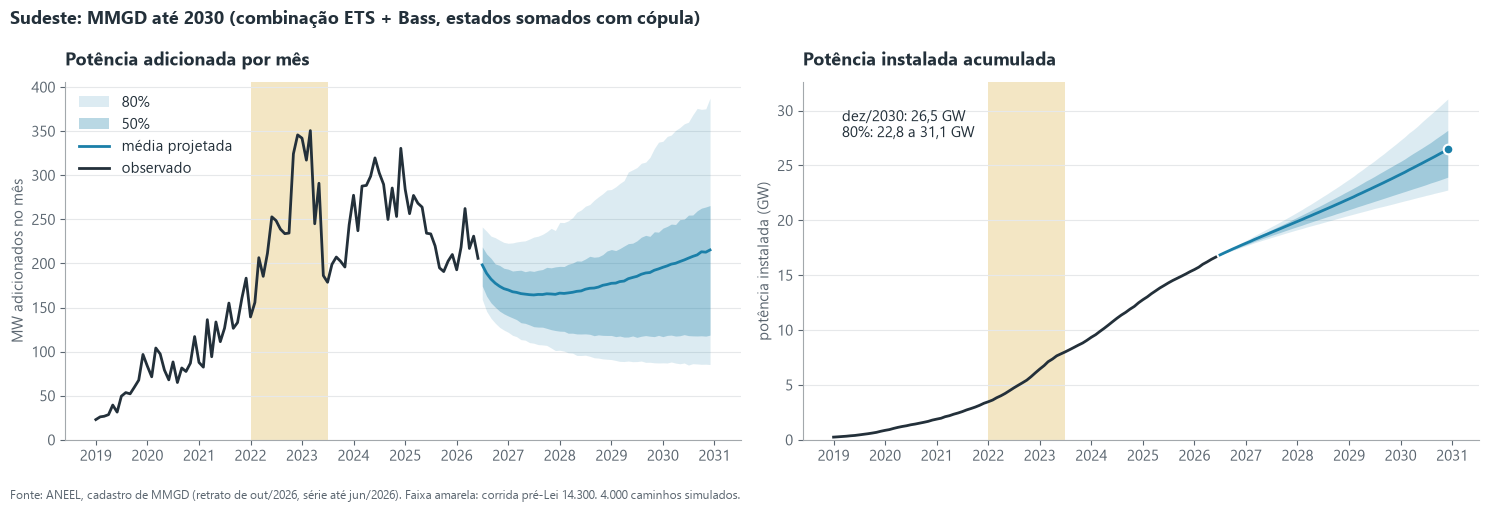

In [4]:
central = {uf: base[uf] for uf in UFS}
mensal_se = sum(central[uf] for uf in UFS)
acum_se = somas["soma com cópula"]
obs = serie[serie.uf == "SE"].set_index("mes")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, hist, sim, esc, rot in [
    (axes[0], obs["mw"], mensal_se, 1, "MW adicionados no mês"),
    (axes[1], obs["mw_acumulado"], acum_se, 1e3, "potência instalada (GW)"),
]:
    q = {p: np.quantile(sim, p, axis=1) / esc for p in (0.1, 0.25, 0.5, 0.75, 0.9)}
    ax.axvspan(*M.CORRIDA, color=estilo.DESTAQUE, lw=0, zorder=0)
    ax.fill_between(FUT, q[0.1], q[0.9], color=CORES_UF["SP"], alpha=0.15, lw=0, label="80%")
    ax.fill_between(FUT, q[0.25], q[0.75], color=CORES_UF["SP"], alpha=0.3, lw=0, label="50%")
    ax.plot(FUT, sim.mean(axis=1) / esc, color=CORES_UF["SP"], lw=2, label="média projetada")
    ax.plot(hist["2019-01-01":].index, hist["2019-01-01":] / esc, color=estilo.TINTA, lw=2, label="observado")
    ax.set_ylabel(rot)
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fim = np.quantile(acum_se[-1], [0.1, 0.9]) / 1e3
txt = f"dez/2030: {acum_se[-1].mean() / 1e3:.1f} GW\n80%: {fim[0]:.1f} a {fim[1]:.1f} GW".replace(".", ",")
axes[1].text(pd.Timestamp("2019-03-01"), fim[1] * 0.97, txt, ha="left", va="top", fontsize=10.5, color=estilo.TINTA)
axes[1].plot([FUT[-1]], [acum_se[-1].mean() / 1e3], "o", ms=7, color=CORES_UF["SP"], mec="white", mew=1.5)
axes[0].legend(loc="upper left")
axes[0].set_title("Potência adicionada por mês")
axes[1].set_title("Potência instalada acumulada")
fig.suptitle("Sudeste: MMGD até 2030 (combinação ETS + Bass, estados somados com cópula)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
estilo.fonte_rodape(fig, "Fonte: ANEEL, cadastro de MMGD (retrato de out/2026, série até jun/2026). Faixa amarela: corrida pré-Lei 14.300. "
                    "4.000 caminhos simulados.")
fig.savefig(RES / "cenarios_leque_se.png")

In [5]:
# por ano: potência adicionada no ano e instalada em dezembro (Sudeste, GW)
anos = FUT.year
linhas = []
for ano in sorted(set(anos)):
    sel = anos == ano
    add = mensal_se[sel].sum(axis=0) / 1e3
    fim = acum_se[sel][-1] / 1e3
    rot = f"{ano} (jul–dez)" if sel.sum() < 12 else str(ano)
    linhas.append({"ano": rot, "adicionada média": add.mean(), "adicionada P10": np.quantile(add, 0.1),
                   "adicionada P90": np.quantile(add, 0.9), "instalada dez média": fim.mean(),
                   "instalada dez P10": np.quantile(fim, 0.1), "instalada dez P90": np.quantile(fim, 0.9)})
hist_ano = obs["mw"].groupby(obs.index.year).sum() / 1e3
print("observado, GW adicionados por ano:", hist_ano.loc[2021:].round(2).to_dict())
pd.DataFrame(linhas).set_index("ano")

observado, GW adicionados por ano: {2021: 1.53, 2022: 2.78, 2023: 2.96, 2024: 3.42, 2025: 2.84, 2026: 1.33}


,adicionada média,adicionada P10,adicionada P90,instalada dez média,instalada dez P10,instalada dez P90
ano,,,,,,
2026 (jul–dez),1.09,0.89,1.31,17.74,17.54,17.96
2027,1.99,1.44,2.64,19.73,19.03,20.52
2028,2.04,1.22,3.09,21.78,20.35,23.48
2029,2.22,1.12,3.60,24.00,21.57,26.97
2030,2.46,1.08,4.27,26.46,22.76,31.06


In [6]:
# por estado em dez/2030 (marginais da simulação conjunta)
por_uf = pd.DataFrame({uf: {**resumo(acumulado(central[uf], uf)[-1]), "jun/2026": acum[uf] / 1e3} for uf in UFS}).T
por_uf["crescimento %"] = 100 * (por_uf["média"] / por_uf["jun/2026"] - 1)
por_uf["parcela da média %"] = 100 * por_uf["média"] / por_uf["média"].sum()
por_uf[["jun/2026", "média", "P10", "P50", "P90", "crescimento %", "parcela da média %"]]

,jun/2026,média,P10,P50,P90,crescimento %,parcela da média %
SP,7.22,12.03,9.51,11.31,15.31,66.71,45.47
MG,6.11,8.73,7.68,8.51,9.99,42.82,32.98
RJ,2.00,3.36,2.67,3.17,4.27,68.17,12.69
ES,1.33,2.34,1.81,2.20,3.04,76.60,8.86


In [7]:
# caminhos do cenário central por UF, para a fase 6 (impacto na rede)
SAIDA = ROOT / "data" / "processed" / "cenarios_2030_caminhos.parquet"
partes = []
for uf in UFS:
    inst = acumulado(central[uf], uf)
    partes.append(pd.DataFrame({
        "mes": np.repeat(FUT, N_SIM), "uf": uf, "caminho": np.tile(np.arange(N_SIM), H),
        "mw_adicionado": central[uf].ravel().astype("float32"), "mw_instalado": inst.ravel().astype("float32"),
    }))
pd.concat(partes, ignore_index=True).to_parquet(SAIDA)
print(f"{SAIDA.relative_to(ROOT)}: {N_SIM} caminhos x {H} meses x {len(UFS)} UFs")

data\processed\cenarios_2030_caminhos.parquet: 4000 caminhos x 54 meses x 4 UFs


**Leitura.**
- **Potência adicionada por mês.** A média cai dos ~205 MW de jun/2026 para ~165 MW em 2027 e volta a ~215 MW no fim de 2030. O
  Bass satura e puxa para baixo; a tendência do ETS puxa para cima no fim do horizonte. Em 2030 o intervalo de 80% vai de ~85 a
  ~385 MW por mês, então o modelo não distingue com segurança entre estagnação e retomada.
- **Por ano**, a projeção é de 2,0 GW em 2027 e 2,5 GW em 2030, abaixo do pico de 3,4 GW de 2024 e perto dos 2,8 GW de 2025. O
  regime pós-corrida, sem volta ao ritmo de 2022–24, é o que a CV da fase 4 premiou.
- **Potência instalada:** 17,7 GW no fim de 2026, 19,7 GW em 2027, 21,8 GW em 2028, 24,0 GW em 2029 e **26,5 GW em dez/2030**
  (80%: 22,8 a 31,1 GW), 59% acima de jun/2026.
- **Por estado:** SP chega a 12,0 GW (45% do Sudeste), MG a 8,7 GW (33%), RJ a 3,4 GW e ES a 2,3 GW. MG é o que menos cresce
  (+43%), o que bate com a fase 3, em que MG foi o único estado com queda clara depois da corrida. RJ e ES crescem 68% e 77%.
- Os caminhos por estado estão em `data/processed/cenarios_2030_caminhos.parquet`, que é a entrada da fase 6.

## 5. Sensibilidade ao modelo

O leque da seção 4 só tem a incerteza do ruído dentro de um modelo. A incerteza sobre qual modelo descreve o futuro é maior.
Aqui os outros candidatos da fase 4 são projetados com os mesmos choques da cópula e somados do mesmo jeito. Cada um
corresponde a um cenário: o ritmo recente continua (naïve), o regime pós-corrida continua (tendência quebrada e intervenção),
o crescimento perde força aos poucos (ETS) e o mercado satura (Bass).

In [8]:
CENARIOS = ["naïve", "ETS(A,Ad,N)", "tendência quebrada (d=0)", "intervenção (d=1)", "Bass",
            "comb. quebrada + Bass", "comb. ETS + Bass"]
fabricas = M.candidatos()
tab_modelos = {}
for nome in CENARIOS:
    sims = base if nome == "comb. ETS + Bass" else M.simular_conjunto(fabricas[nome], y, {uf: z[uf] for uf in UFS}, H)
    tab_modelos[nome] = sum(acumulado(sims[uf], uf) for uf in UFS)
tab_mod = pd.DataFrame({k: resumo(v[-1]) for k, v in tab_modelos.items()}).T
cv = pd.read_parquet(ROOT / "data" / "interim" / "cv_fase4.parquet")
tab_mod["CRPS log (CV, SE)"] = M.resumo_cv(cv[cv.uf == "SE"])["CRPS log"]
tab_mod.sort_values("média")

,média,P10,P50,P90,P90 − P10,"CRPS log (CV, SE)"
Bass,18.65,18.44,18.64,18.88,0.44,0.43
comb. quebrada + Bass,23.92,21.99,23.51,26.11,4.11,0.10
comb. ETS + Bass,26.46,22.76,25.70,31.06,8.30,0.09
tendência quebrada (d=0),29.18,25.40,28.37,33.53,8.13,0.17
"ETS(A,Ad,N)",34.27,27.07,32.79,43.28,16.21,0.18
intervenção (d=1),51.57,23.06,32.17,88.76,65.70,0.21
naïve,73.01,23.87,39.36,122.96,99.09,0.16


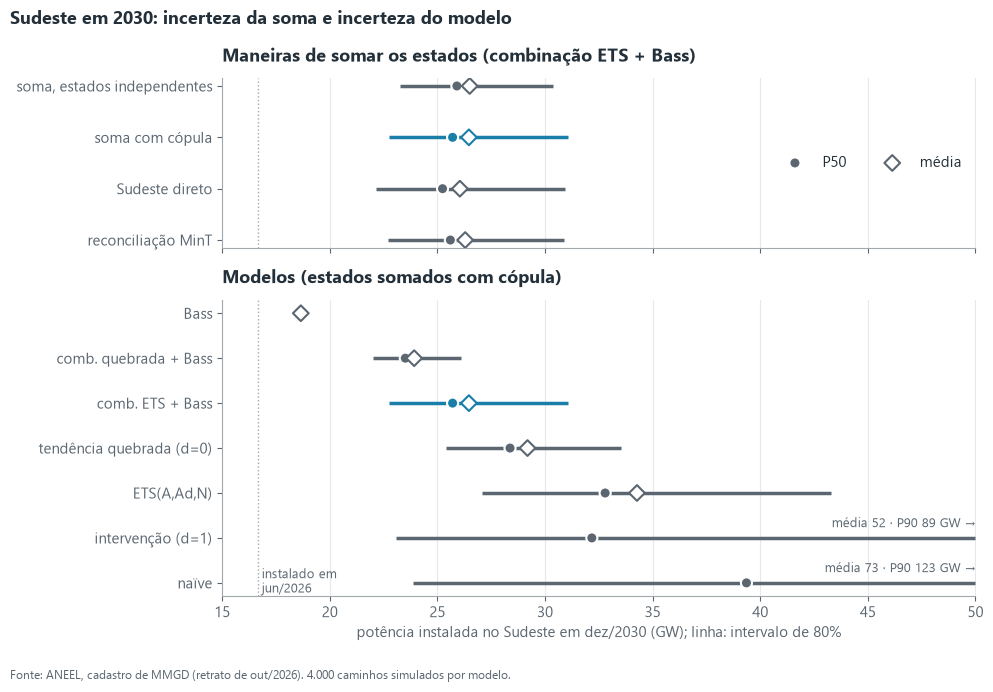

In [9]:
XMAX = 50  # naïve e intervenção passam disso; o valor vai escrito na ponta
fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True, gridspec_kw={"height_ratios": [4, 7]})
for ax, tab, destaque in [(axes[0], tab_metodos, "soma com cópula"),
                          (axes[1], tab_mod.sort_values("média"), "comb. ETS + Bass")]:
    yy = np.arange(len(tab))
    cores = [CORES_UF["SP"] if i == destaque else estilo.TINTA_SUAVE for i in tab.index]
    ax.axvline(acum["SE"] / 1e3, color=estilo.NEUTRO, lw=1, ls=":")
    ax.hlines(yy, tab["P10"], tab["P90"].clip(upper=XMAX), color=cores, lw=2.5)
    ax.scatter(tab["P50"], yy, s=64, color=cores, edgecolor="white", linewidth=1.5, zorder=3, label="P50")
    dentro = tab["média"] <= XMAX
    ax.scatter(tab["média"][dentro], yy[dentro.to_numpy()], s=64, marker="D", facecolor="white",
               edgecolor=np.array(cores)[dentro.to_numpy()], linewidth=1.5, zorder=3, label="média")
    for j, (nome, r) in enumerate(tab.iterrows()):
        if r["P90"] > XMAX:
            ax.text(XMAX, j - 0.18, f"média {r['média']:.0f} · P90 {r['P90']:.0f} GW →", ha="right", va="bottom",
                    fontsize=9, color=estilo.TINTA_SUAVE)
    ax.set_yticks(yy, tab.index)
    ax.invert_yaxis()
    ax.grid(axis="x", color=estilo.GRADE)
    ax.grid(axis="y", visible=False)
axes[1].set_xlim(15, XMAX)
axes[0].set_title("Maneiras de somar os estados (combinação ETS + Bass)")
axes[1].set_title("Modelos (estados somados com cópula)")
axes[0].legend(loc="center right", ncol=2)
axes[1].text(acum["SE"] / 1e3, len(tab_mod) - 0.7, " instalado em\n jun/2026", color=estilo.TINTA_SUAVE, fontsize=9,
             va="bottom")
axes[1].set_xlabel("potência instalada no Sudeste em dez/2030 (GW); linha: intervalo de 80%")
fig.suptitle("Sudeste em 2030: incerteza da soma e incerteza do modelo", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
estilo.fonte_rodape(fig, "Fonte: ANEEL, cadastro de MMGD (retrato de out/2026). 4.000 caminhos simulados por modelo.")
fig.savefig(RES / "cenarios_2030_metodos_modelos.png")

**Leitura.**
- **A incerteza sobre o modelo é maior que a incerteza dentro do modelo.** Deixando de lado o Bass (um piso), o naïve e o de
  intervenção (que não servem para esse horizonte, abaixo), a média de dez/2030 vai de 23,9 GW (combinação com tendência quebrada) a 34,3 GW (ETS sozinho). Isso é mais que o
  intervalo de 80% do cenário central (22,8 a 31,1 GW).
- **Bass (18,7 GW) é um piso.** O mercado satura quase onde está, com só 2 GW a mais em 4,5 anos. O intervalo de 0,4 GW é estreito
  porque o Bass não carrega a incerteza do $m$, que é o parâmetro mais incerto.
- **ETS sozinho (34,3 GW) é um teto plausível:** o crescimento de antes continua, só um pouco amortecido. A tendência quebrada
  (29,2 GW) projeta a inclinação do regime pós-corrida.
- **Naïve e intervenção ($d = 1$) não servem para 2030.** As medianas (39 e 32 GW) até são parecidas com as demais, mas a média
  (73 e 52 GW) e o P90 (123 e 89 GW) explodem. Num passeio aleatório no log, a incerteza se acumula por 54 meses e a cauda
  lognormal domina. No de intervenção, quem domina é a incerteza da inclinação do último regime.
- O cenário central (26,5 GW) fica no meio dos modelos plausíveis e é o de menor CRPS. Faixa de leitura para o relatório:
  **cerca de 26 GW, com 80% de chance entre 23 e 31 GW, e de 24 a 34 GW conforme a hipótese sobre o crescimento.**

## Conclusões

1. **O Sudeste deve chegar a dez/2030 com cerca de 26,5 GW de MMGD instalados** (80%: 22,8 a 31,1 GW), contra 16,7 GW em jun/2026.
   São de 6 a 14 GW a mais, com 10 GW no cenário central.
2. **O ritmo anual fica entre 2 e 2,5 GW**, abaixo do pico de 3,4 GW de 2024. O cenário central mantém o regime pós-corrida, sem
   volta ao ritmo de 2022–24 e sem parada.
3. **A dependência entre os estados importa para o leque, não para o centro.** A cópula alarga o intervalo de 80% do Sudeste em
   17%. A soma dos estados, a previsão direta e a reconciliação MinT diferem em menos de 0,5 GW.
4. **A maior incerteza é sobre o modelo:** de 18,7 GW (Bass, o mercado satura) a 34,3 GW (ETS, o crescimento continua).
5. SP segue com quase metade da potência (12 GW); MG é o estado que menos cresce.

**Limitações.**
- Os leques do ETS e do Bass não incluem incerteza dos parâmetros. Em 4,5 anos, a do $m$ do Bass e a do amortecimento $\phi$ do
  ETS podem ser maiores que a do ruído. A seção 5 cobre isso só em parte, ao trocar de modelo.
- A CV da fase 4 cobre um só ano de origens, todas no regime pós-corrida.
- A transição tarifária da Lei 14.300 (o pagamento do fio B sobe até 2029) não entra de forma explícita. Ela age por meio da
  tendência que os modelos já estimaram.
- O cadastro só traz usinas ativas e os dois últimos meses do retrato foram cortados (fase 1).

**Para a fase 6:** os 4.000 caminhos por estado de `cenarios_2030_caminhos.parquet` multiplicados pelo perfil horário de radiação
do INMET dão a geração de MMGD ao meio-dia em 2030, para comparar com a carga do ONS.